In [3]:
import pandas as pd

In [4]:
raw_data = pd.read_csv('fake_job_postings.csv')

In [5]:
raw_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17880 entries, 0 to 17879
Data columns (total 18 columns):
 #   Column               Non-Null Count  Dtype 
---  ------               --------------  ----- 
 0   job_id               17880 non-null  int64 
 1   title                17880 non-null  object
 2   location             17534 non-null  object
 3   department           6333 non-null   object
 4   salary_range         2868 non-null   object
 5   company_profile      14572 non-null  object
 6   description          17879 non-null  object
 7   requirements         15184 non-null  object
 8   benefits             10668 non-null  object
 9   telecommuting        17880 non-null  int64 
 10  has_company_logo     17880 non-null  int64 
 11  has_questions        17880 non-null  int64 
 12  employment_type      14409 non-null  object
 13  required_experience  10830 non-null  object
 14  required_education   9775 non-null   object
 15  industry             12977 non-null  object
 16  func

In [6]:
raw_data.describe(include=['object'])

,title,location,department,salary_range,company_profile,description,requirements,benefits,employment_type,required_experience,required_education,industry,function
count,17880,17534,6333,2868,14572,17879,15184,10668,14409,10830,9775,12977,11425
unique,11231,3105,1337,874,1709,14801,11967,6204,5,7,13,131,37
top,English Teacher Abroad,"GB, LND, London",Sales,0-0,We help teachers get safe &amp; secure jobs ab...,"Play with kids, get paid for it Love travel? J...",University degree required. TEFL / TESOL / CEL...,See job description,Full-time,Mid-Senior level,Bachelor's Degree,Information Technology and Services,Information Technology
freq,311,718,551,142,726,379,410,726,11620,3809,5145,1734,1749


In [7]:
raw_data.describe(include=['int64'])

,job_id,telecommuting,has_company_logo,has_questions,fraudulent
count,17880.000000,17880.000000,17880.000000,17880.000000,17880.000000
mean,8940.500000,0.042897,0.795302,0.491723,0.048434
std,5161.655742,0.202631,0.403492,0.499945,0.214688
min,1.000000,0.000000,0.000000,0.000000,0.000000
25%,4470.750000,0.000000,1.000000,0.000000,0.000000
50%,8940.500000,0.000000,1.000000,0.000000,0.000000
75%,13410.250000,0.000000,1.000000,1.000000,0.000000
max,17880.000000,1.000000,1.000000,1.000000,1.000000


In [8]:
raw_data.isnull().sum()

,0
job_id,0
title,0
location,346
department,11547
salary_range,15012
company_profile,3308
description,1
requirements,2696
benefits,7212
telecommuting,0


In [9]:
raw_data.nunique()

,0
job_id,17880
title,11231
location,3105
department,1337
salary_range,874
company_profile,1709
description,14801
requirements,11967
benefits,6204
telecommuting,2


In [10]:
raw_data.head(2)

,job_id,title,location,department,salary_range,company_profile,description,requirements,benefits,telecommuting,has_company_logo,has_questions,employment_type,required_experience,required_education,industry,function,fraudulent
0,1,Marketing Intern,"US, NY, New York",Marketing,NaN,"We're Food52, and we've created a groundbreaki...","Food52, a fast-growing, James Beard Award-winn...",Experience with content management systems a m...,NaN,0,1,0,Other,Internship,NaN,NaN,Marketing,0
1,2,Customer Service - Cloud Video Production,"NZ, , Auckland",Success,NaN,"90 Seconds, the worlds Cloud Video Production ...",Organised - Focused - Vibrant - Awesome!Do you...,What we expect from you:Your key responsibilit...,What you will get from usThrough being part of...,0,1,0,Full-time,Not Applicable,NaN,Marketing and Advertising,Customer Service,0


In [11]:
raw_data.groupby('fraudulent')['job_id'].count()

,job_id
fraudulent,
0,17014
1,866


In [12]:
raw_data.drop(columns=['salary_range','department'],inplace=True)

In [13]:
raw_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17880 entries, 0 to 17879
Data columns (total 16 columns):
 #   Column               Non-Null Count  Dtype 
---  ------               --------------  ----- 
 0   job_id               17880 non-null  int64 
 1   title                17880 non-null  object
 2   location             17534 non-null  object
 3   company_profile      14572 non-null  object
 4   description          17879 non-null  object
 5   requirements         15184 non-null  object
 6   benefits             10668 non-null  object
 7   telecommuting        17880 non-null  int64 
 8   has_company_logo     17880 non-null  int64 
 9   has_questions        17880 non-null  int64 
 10  employment_type      14409 non-null  object
 11  required_experience  10830 non-null  object
 12  required_education   9775 non-null   object
 13  industry             12977 non-null  object
 14  function             11425 non-null  object
 15  fraudulent           17880 non-null  int64 
dtypes: i

In [14]:
continuous_cols = [
    'job_id',
    'telecommuting',
    'has_company_logo',
    'has_questions',
    'fraudulent'
]
categorical_cols = [
    'title',
    'location',
    'department',
    'company_profile',
    'requirements',
    'benefits',
    'employment_type',
    'required_experience',
    'required_education',
    'industry',
    'function'
]

In [15]:
sub_categorical_cols = [
    'location',
    'employment_type',
    'required_experience',
    'required_education',
    'industry',
    'function'
]
raw_data[sub_categorical_cols] = raw_data[sub_categorical_cols].fillna('Unknown')

In [16]:
raw_data.dropna(subset=['description'], inplace=True)

In [17]:
text_cols = ['company_profile', 'requirements', 'benefits']
raw_data[text_cols] = raw_data[text_cols].fillna('Unknown')

In [18]:
raw_data.isnull().sum()

,0
job_id,0
title,0
location,0
company_profile,0
description,0
requirements,0
benefits,0
telecommuting,0
has_company_logo,0
has_questions,0


In [19]:
import regex as re
import nltk
from nltk.corpus import stopwords

In [20]:
nltk.download('stopwords')

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


True

In [21]:
stopwords_set = set(stopwords.words('english'))

In [22]:
stopwords_set

{'a',
 'about',
 'above',
 'after',
 'again',
 'against',
 'ain',
 'all',
 'am',
 'an',
 'and',
 'any',
 'are',
 'aren',
 "aren't",
 'as',
 'at',
 'be',
 'because',
 'been',
 'before',
 'being',
 'below',
 'between',
 'both',
 'but',
 'by',
 'can',
 'couldn',
 "couldn't",
 'd',
 'did',
 'didn',
 "didn't",
 'do',
 'does',
 'doesn',
 "doesn't",
 'doing',
 'don',
 "don't",
 'down',
 'during',
 'each',
 'few',
 'for',
 'from',
 'further',
 'had',
 'hadn',
 "hadn't",
 'has',
 'hasn',
 "hasn't",
 'have',
 'haven',
 "haven't",
 'having',
 'he',
 "he'd",
 "he'll",
 "he's",
 'her',
 'here',
 'hers',
 'herself',
 'him',
 'himself',
 'his',
 'how',
 'i',
 "i'd",
 "i'll",
 "i'm",
 "i've",
 'if',
 'in',
 'into',
 'is',
 'isn',
 "isn't",
 'it',
 "it'd",
 "it'll",
 "it's",
 'its',
 'itself',
 'just',
 'll',
 'm',
 'ma',
 'me',
 'mightn',
 "mightn't",
 'more',
 'most',
 'mustn',
 "mustn't",
 'my',
 'myself',
 'needn',
 "needn't",
 'no',
 'nor',
 'not',
 'now',
 'o',
 'of',
 'off',
 'on',
 'once',
 'on

In [23]:
def preprocess(text):
  if isinstance(text,str):
    text = re.sub(r'<.*?>', '',text)
    text = re.sub(r'[^a-zA-Z\s]', '',text)
    text = text.lower()
    words = text.split()
    words = [word for word in words if word not in stopwords_set]
    return ' '.join(words)
  return text

In [24]:
text_cols.extend(['title','description'])

In [25]:
raw_data[text_cols] = raw_data[text_cols].map(preprocess)

In [26]:
empty_strings = (raw_data[text_cols] == '').sum()
print("Empty strings in each text column:\n", empty_strings)


Empty strings in each text column:
 company_profile     0
requirements        8
benefits           29
title               0
description         1
dtype: int64


In [27]:
text_lengths = raw_data[text_cols].map(len)
print("Length of text in each column after preprocessing:\n", text_lengths)


Length of text in each column after preprocessing:
        company_profile  requirements  benefits  title  description
0                  642           671         7     16          706
1                  884          1076       786     39         1543
2                  614          1103         7     37          274
3                  478          1209       687     31         2094
4                 1331           648        21     19         1226
...                ...           ...       ...    ...          ...
17875             1229           990       509     29         1020
17876             1624           530       465     18         1004
17877              182           879         7     55         1083
17878                7           362       157     16          356
17879             1229           698         7     26         1279

[17879 rows x 5 columns]


In [28]:
raw_data = raw_data[raw_data['description'] != '']
raw_data['requirements'].replace('', 'Unknown', inplace=True)
raw_data['benefits'].replace('', 'Unknown', inplace=True)
empty_strings = (raw_data[text_cols] == '').sum()
print("Empty strings after fixing:\n", empty_strings)

Empty strings after fixing:
 company_profile    0
requirements       0
benefits           0
title              0
description        0
dtype: int64


<ipython-input-28-9c758c60aa37>:2: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  raw_data['requirements'].replace('', 'Unknown', inplace=True)
<ipython-input-28-9c758c60aa37>:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  raw_data['requirements'].replace('', 'Unknown', inplace=True)
<ipython-input-28-9c758c60aa37>:3: FutureWarning: A value i

In [29]:
df=raw_data.copy()

In [30]:
from sklearn.feature_extraction.text import TfidfVectorizer

In [31]:
tfidf_vectorizer = TfidfVectorizer(max_features=5000, ngram_range=(1,2))

In [32]:
x_tfidf = tfidf_vectorizer.fit_transform(df['description'])
y = df['fraudulent']

In [33]:
from sklearn.model_selection import train_test_split

In [34]:
X_train, X_test, y_train, y_test = train_test_split(x_tfidf, y, test_size =0.2, random_state=42, stratify=y)

In [35]:
from sklearn.linear_model import LogisticRegression
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

In [36]:
log_reg = LogisticRegression(max_iter=1000)
log_reg.fit(X_train, y_train)

y_pred_log = log_reg.predict(X_test)

log_reg_results = {
    "Accuracy": accuracy_score(y_test, y_pred_log),
    "Precision": precision_score(y_test, y_pred_log),
    "Recall": recall_score(y_test, y_pred_log),
    "F1 Score": f1_score(y_test, y_pred_log)
}

print("Logistic Regression Results:", log_reg_results)


Logistic Regression Results: {'Accuracy': 0.9689597315436241, 'Precision': 1.0, 'Recall': 0.3583815028901734, 'F1 Score': 0.5276595744680851}


In [37]:
xgb_model = XGBClassifier(use_label_encoder=False, eval_metric='logloss')
xgb_model.fit(X_train, y_train)
y_pred_xgb = xgb_model.predict(X_test)
xgb_results = {
    "Accuracy": accuracy_score(y_test, y_pred_xgb),
    "Precision": precision_score(y_test, y_pred_xgb),
    "Recall": recall_score(y_test, y_pred_xgb),
    "F1 Score": f1_score(y_test, y_pred_xgb)
}

print("XGBoost Results:", xgb_results)


/usr/local/lib/python3.11/dist-packages/xgboost/core.py:158: UserWarning: [14:54:57] WARNING: /workspace/src/learner.cc:740: 
Parameters: { "use_label_encoder" } are not used.

  warnings.warn(smsg, UserWarning)


XGBoost Results: {'Accuracy': 0.9801454138702461, 'Precision': 0.9722222222222222, 'Recall': 0.6069364161849711, 'F1 Score': 0.7473309608540926}


In [49]:
import nltk
from nltk.stem import WordNetLemmatizer
from nltk import pos_tag, word_tokenize
from nltk.corpus import wordnet

nltk.download('punkt')
nltk.download('averaged_perceptron_tagger_eng')
nltk.download('wordnet')

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package averaged_perceptron_tagger_eng to
[nltk_data]     /root/nltk_data...
[nltk_data]   Unzipping taggers/averaged_perceptron_tagger_eng.zip.
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!


True

In [39]:
df['text_input'] = df['description'] + ' ' + df['requirements']

In [47]:
def get_wordnet_pos(tag):
    if tag.startswith('J'):
        return wordnet.ADJ
    elif tag.startswith('V'):
        return wordnet.VERB
    elif tag.startswith('N'):
        return wordnet.NOUN
    elif tag.startswith('R'):
        return wordnet.ADV
    else:
        return wordnet.NOUN

In [50]:
lemmatizer = WordNetLemmatizer()
def lemmatize_text(text):
    if isinstance(text, str):
        tokens = word_tokenize(text)
        pos_tags = pos_tag(tokens)
        lemmas = [lemmatizer.lemmatize(word, get_wordnet_pos(tag)) for word, tag in pos_tags]
        return ' '.join(lemmas)
    return text

In [ ]:
df['lemmatized_text'] = df['text_input'].apply(lemmatize_text)

In [51]:
df['text_input'].head(10)

,text_input
0,food fastgrowing james beard awardwinning onli...
1,organised focused vibrant awesomedo passion cu...
2,client located houston actively seeking experi...
3,company esri environmental systems research in...
4,job title itemization review managerlocation f...
5,job overviewapex environmental consulting firm...
6,responsibilities manage englishspeaking editor...
7,airenvyhey seasoned entrepreneurs heart san fr...
8,implementationconfigurationtestingtraining onh...
9,customer service associate based phoenix az ri...


In [52]:
df['lemmatized_text'].head(10)

,lemmatized_text
0,food fastgrowing james beard awardwinning onli...
1,organise focused vibrant awesomedo passion cus...
2,client locate houston actively seek experience...
3,company esri environmental system research ins...
4,job title itemization review managerlocation f...
5,job overviewapex environmental consulting firm...
6,responsibility manage englishspeaking editoria...
7,airenvyhey season entrepreneur heart san franc...
8,implementationconfigurationtestingtraining onh...
9,customer service associate base phoenix az rig...


In [54]:
import numpy as np

In [55]:
glove_path = 'glove.6B.100d.txt'
embedding_index = {}
with open(glove_path, encoding="utf8") as f:
    for line in f:
        values = line.split()
        word = values[0]
        coef = np.asarray(values[1:], dtype='float32')
        embedding_index[word] = coef


In [59]:
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

MAX_NUM_WORDS = 10000
MAX_SEQUENCE_LENGTH = 100

# Recreate the tokenizer and fit on your lemmatized input
tokenizer = Tokenizer(num_words=MAX_NUM_WORDS, oov_token="<OOV>")
tokenizer.fit_on_texts(df['lemmatized_text'])

# Generate sequences and pad them (if needed)
sequences = tokenizer.texts_to_sequences(df['lemmatized_text'])
X_padded = pad_sequences(sequences, maxlen=MAX_SEQUENCE_LENGTH, padding='post', truncating='post')

# Target variable
y = df['fraudulent'].values


In [60]:
EMBEDDING_DIM = 100

embedding_matrix = np.zeros((MAX_NUM_WORDS, EMBEDDING_DIM))
for word, i in tokenizer.word_index.items():
    if i < MAX_NUM_WORDS:
        embedding_vector = embedding_index.get(word)
        if embedding_vector is not None:
            embedding_matrix[i] = embedding_vector


In [62]:
embedding_matrix

array([[ 0.        ,  0.        ,  0.        , ...,  0.        ,
         0.        ,  0.        ],
       [ 0.        ,  0.        ,  0.        , ...,  0.        ,
         0.        ,  0.        ],
       [-0.11619   ,  0.45447001, -0.69216001, ..., -0.54737002,
         0.48822001,  0.32246   ],
       ...,
       [ 0.        ,  0.        ,  0.        , ...,  0.        ,
         0.        ,  0.        ],
       [-0.045084  ,  0.52582002, -0.011874  , ..., -1.62600005,
        -0.42636001,  0.42605001],
       [ 0.        ,  0.        ,  0.        , ...,  0.        ,
         0.        ,  0.        ]])

In [63]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout

In [64]:
model = Sequential([
    Embedding(
        input_dim=MAX_NUM_WORDS,
        output_dim=EMBEDDING_DIM,
        weights=[embedding_matrix],
        input_length=MAX_SEQUENCE_LENGTH,
        trainable=False  # Keep GloVe embeddings fixed
    ),
    LSTM(128, return_sequences=False),
    Dropout(0.5),
    Dense(64, activation='relu'),
    Dropout(0.3),
    Dense(1, activation='sigmoid')  # Binary classification
])

/usr/local/lib/python3.11/dist-packages/keras/src/layers/core/embedding.py:90: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


In [65]:
# Compile the model
model.compile(loss='binary_crossentropy', optimizer='adam', metrics=['accuracy'])

In [66]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ embedding (Embedding)                │ ?                           │       1,000,000 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ lstm (LSTM)                          │ ?                           │     0 (unbuilt) │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ ?                           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ ?                           │     0 (unbuilt) │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_1 (Dropout)                  │ ?                           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ ?                           │     0 (unbuilt) │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 1,000,000 (3.81 MB)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 1,000,000 (3.81 MB)

In [67]:
from sklearn.model_selection import train_test_split

In [68]:
X_train, X_test, y_train, y_test = train_test_split(X_padded, y, test_size=0.2, random_state=42, stratify=y)
history = model.fit(X_train, y_train, epochs=5, batch_size=64, validation_split=0.2)

Epoch 1/5
179/179 ━━━━━━━━━━━━━━━━━━━━ 50s 241ms/step - accuracy: 0.9345 - loss: 0.2666 - val_accuracy: 0.9535 - val_loss: 0.1859
Epoch 2/5
179/179 ━━━━━━━━━━━━━━━━━━━━ 40s 222ms/step - accuracy: 0.9477 - loss: 0.2090 - val_accuracy: 0.9535 - val_loss: 0.1852
Epoch 3/5
179/179 ━━━━━━━━━━━━━━━━━━━━ 41s 223ms/step - accuracy: 0.9536 - loss: 0.1865 - val_accuracy: 0.9535 - val_loss: 0.1855
Epoch 4/5
179/179 ━━━━━━━━━━━━━━━━━━━━ 40s 215ms/step - accuracy: 0.9530 - loss: 0.1802 - val_accuracy: 0.9535 - val_loss: 0.1825
Epoch 5/5
179/179 ━━━━━━━━━━━━━━━━━━━━ 40s 208ms/step - accuracy: 0.9455 - loss: 0.2002 - val_accuracy: 0.9535 - val_loss: 0.1833


In [69]:
loss, accuracy = model.evaluate(X_test, y_test)
print(f"\nTest Accuracy: {accuracy:.4f}")

112/112 ━━━━━━━━━━━━━━━━━━━━ 12s 103ms/step - accuracy: 0.9542 - loss: 0.1778

Test Accuracy: 0.9516


In [70]:
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

In [71]:
# Predict on the test set
y_pred_probs = model.predict(X_test)
y_pred = (y_pred_probs > 0.5).astype("int32").flatten()

112/112 ━━━━━━━━━━━━━━━━━━━━ 13s 114ms/step


In [72]:
# Print classification report
print("Classification Report:")
print(classification_report(y_test, y_pred, target_names=["Real", "Fraudulent"]))

Classification Report:
              precision    recall  f1-score   support

        Real       0.95      1.00      0.98      3403
  Fraudulent       0.00      0.00      0.00       173

    accuracy                           0.95      3576
   macro avg       0.48      0.50      0.49      3576
weighted avg       0.91      0.95      0.93      3576



/usr/local/lib/python3.11/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.11/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.11/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


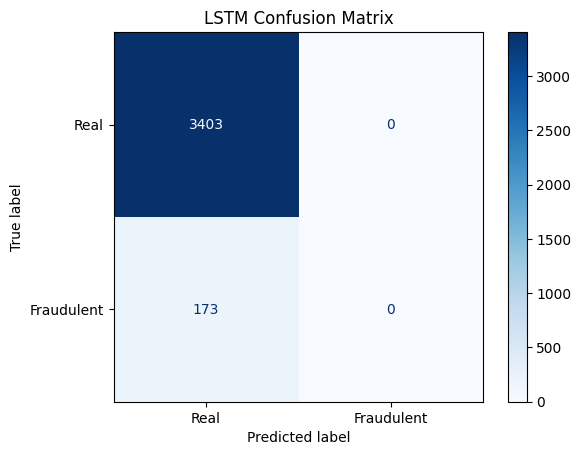

In [73]:
# Confusion matrix
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Real", "Fraudulent"])
disp.plot(cmap=plt.cm.Blues)
plt.title("LSTM Confusion Matrix")
plt.show()
